# Lecture 17 notebook: an intraday grid on the tape

This notebook replays Lecture 17 on the tape of Lecture 12. Every figure and number of the lecture comes from a script in `scripts/`, next to this
notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | How a grid earns: the per-second table, one day fill by fill | §1 |
| 2 | Where the profit comes from: Monte Carlo without a pattern, with jumps, with runs | §2 |
| 3 | The tape, against the same minutes shuffled | §3 |
| 4 | The levers: size profiles, width, exits and refresh | §4 |
| 5 | Known in advance: the rules and the Benjamini–Hochberg correction | §5 |
| 6 | Next to the trend rule | §6 |
| 7 | The rebate that would close the gap | §7 |
| 8 | A test of your own | §8.2 |

**Before you start.** Lecture 12's notebook must have built the tape for October 2021 to September 2026, and Lecture 16's notebook its results
(§6 uses the trend rule). Results go to `data/interim/l17`; figures are saved in `figures/` as `nb_*`, so the lecture's own figures are never
overwritten. The tape runs of §3 to §5 take between a quarter of an hour and an hour each; they are skipped when their results exist, unless
`REBUILD = True`. The whole notebook, from nothing, takes a few hours.

## 0. Settings

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, Markdown, display

HERE = Path.cwd()
SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS), str(HERE.parent / "16-trend-on-the-tape" / "scripts"), str(HERE.parent / "12-tick-data-the-tape"), str(HERE.parents[1])]
import tape
OUT = tape.ROOT / "interim" / "l17"; OUT.mkdir(parents=True, exist_ok=True)
REBUILD = False                                                            # True: rerun the tape runs even if their results exist

pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", "the folder in the environment variable TAPE_ROOT" if os.environ.get("TAPE_ROOT") else "data/ at the top of the repository")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, makes=None, show=False):
    """Run a script of scripts/ in a fresh process; figures to figures/ as nb_*, results to data/interim/l17.
    makes: the result file the script writes; if it exists and REBUILD is False, the script is skipped."""
    if makes and (OUT / makes).exists() and not REBUILD:
        print(f"{script}: skipped, {makes} exists"); return
    t0 = time.time()
    env = {**os.environ, "TAPE_ROOT": str(tape.ROOT), "L17_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def result(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))


def period(df):
    return df.with_columns(pl.when(pl.col("year") <= 2024).then(pl.lit("2021-24")).otherwise(pl.lit("2025-26")).alias("period"))


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)

data folder: the folder in the environment variable TAPE_ROOT
free memory: 2.6 GB of 16.9 GB


## 1. How a grid earns

Lecture §1. The per-second table the simulator runs on (for every second with trades: the highest price paid by aggressive buyers, the lowest received
by aggressive sellers, the last price), built once from the tape; then 12 March 2024, fill by fill, with a step-by-step copy of the simulator whose
day totals must equal the simulator's (figure 17_01).

l17_seconds.py: 1 s


l17_day_log.py: 11 s
gross         log -0.512293  simulator -0.512293
trips_income  log +3.625000  simulator +3.625000
inventory     log -4.137293  simulator -4.137293
maker_fee     log +0.359830  simulator +0.359830
taker_fee     log +0.182276  simulator +0.182276
funding       log -0.011921  simulator -0.011921
net           log -1.066321  simulator -1.066321
trips         log +29.000000  simulator +29.000000
stops         log +3.000000  simulator +3.000000
shape: (80, 5)
┌──────────┬─────────────┬──────────┬──────────┬─────────┐
│ time     ┆ event       ┆ price    ┆ position ┆ centre  │
│ ---      ┆ ---         ┆ ---      ┆ ---      ┆ ---     │
│ time     ┆ str         ┆ f64      ┆ i64      ┆ f64     │
╞══════════╪═════════════╪══════════╪══════════╪═════════╡
│ 01:45:11 ┆ sell        ┆ 72516.78 ┆ -1       ┆ 72156.0 │
│ 03:09:54 ┆ buy         ┆ 72156.0  ┆ 0        ┆ 72156.0 │
│ 03:21:22 ┆ buy         ┆ 71795.22 ┆ 1        ┆ 72156.0 │
│ 03:32:10 ┆ buy         ┆ 71434.44 ┆ 2        ┆ 

l17_s1_chart.py: 6 s


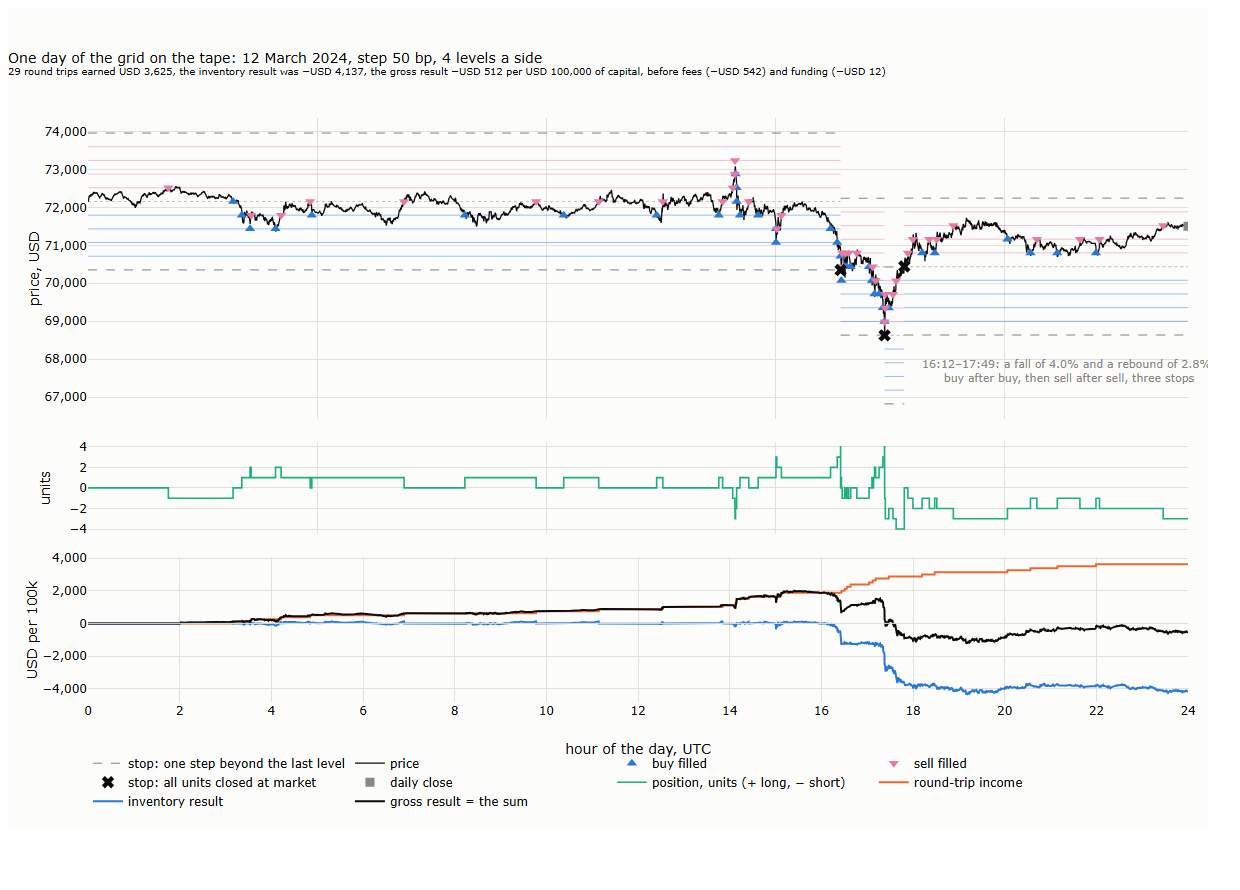

In [2]:
run("l17_seconds.py")
run("l17_day_log.py", show=True)
run("l17_s1_chart.py")
pictures("17_01_grid_day")

## 2. Where the profit comes from

Lecture §2. Monte Carlo, 1,000 simulated days each: a price with no pattern, with jumps, and two controls (figure 17_02); runs with the swings held
fixed, and runs calibrated to the tape's variance ratio and volatility, with the switch seen at once or late (figure 17_03). Each takes a few minutes.

l17_mc.py: skipped, l17_mc.json exists
l17_mc_runs.py: skipped, l17_mc_runs.json exists
l17_mc_calib.py: skipped, l17_mc_calib.json exists


l17_s2_charts.py: 8 s


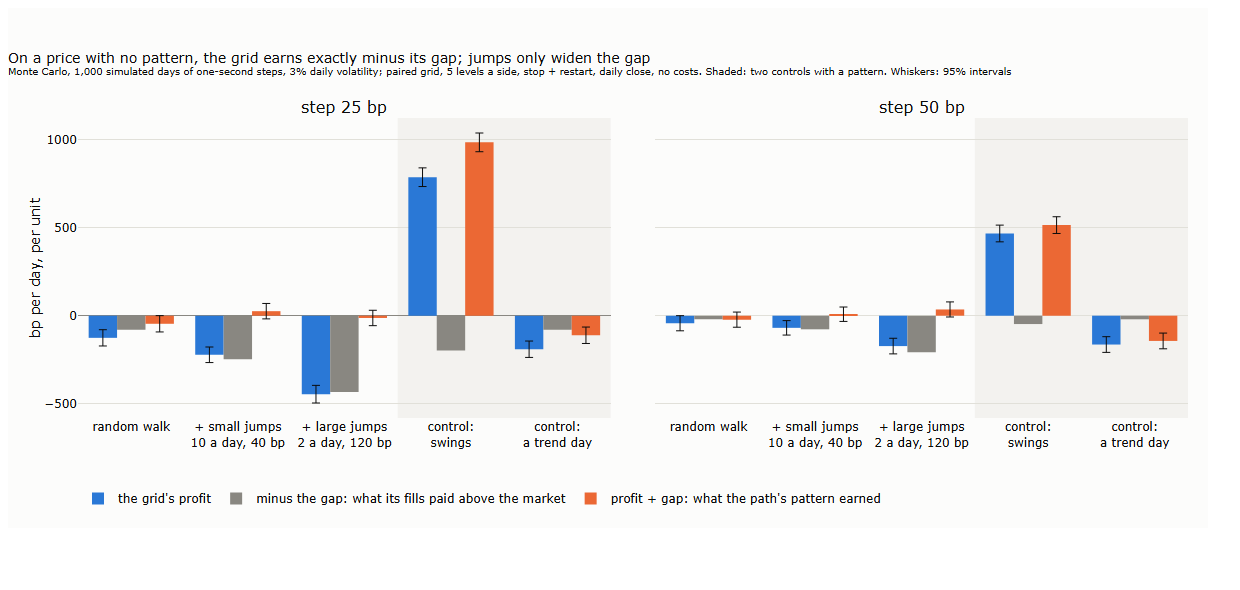

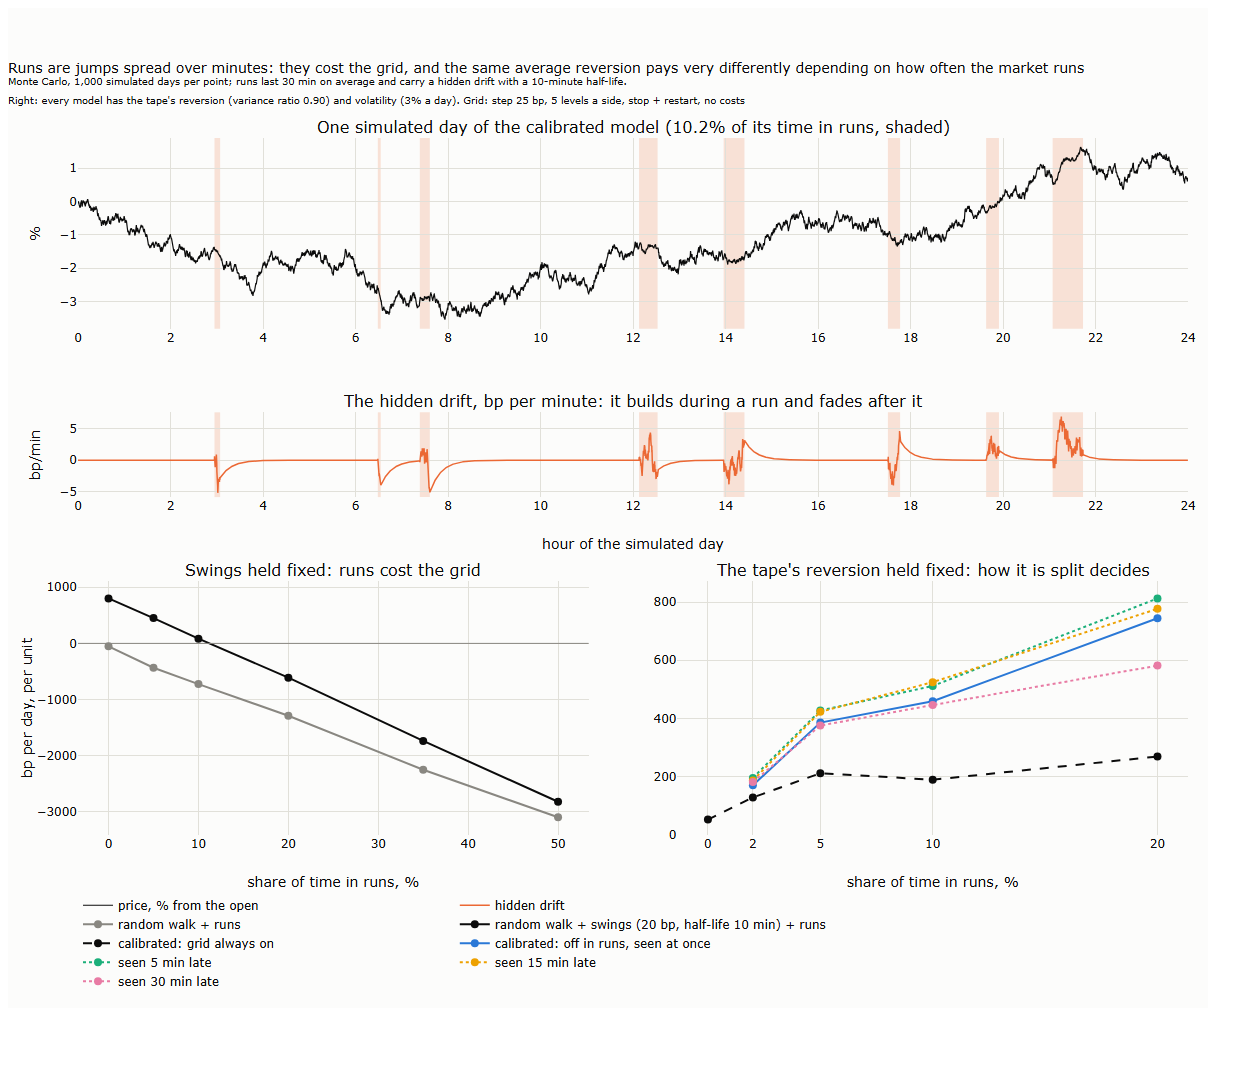

case,profit bp,gap bp,profit + gap,t of profit + gap
str,f64,f64,f64,f64
"""step 25 bp | stop+restart | random walk""",-125.616469,79.712852,-45.903617,-1.945813
"""step 25 bp | stop+restart | random walk + small jumps""",-221.680255,247.316452,25.636196,1.149785
"""step 25 bp | stop+restart | random walk + large jumps""",-445.038699,432.128917,-12.909783,-0.579645
"""step 25 bp | stop+restart | control: reverting part""",785.251499,197.51575,982.767248,36.271559
"""step 25 bp | stop+restart | control: trend days""",-190.209179,79.264887,-110.944292,-4.67182
"""step 50 bp | stop+restart | random walk""",-42.756669,20.291391,-22.465278,-1.02469
"""step 50 bp | stop+restart | random walk + small jumps""",-68.905847,77.292901,8.387054,0.402932
"""step 50 bp | stop+restart | random walk + large jumps""",-172.341027,207.690388,35.349362,1.621739
"""step 50 bp | stop+restart | control: reverting part""",466.165327,47.421678,513.587005,21.213699


In [3]:
run("l17_mc.py", makes="l17_mc.json"); run("l17_mc_runs.py", makes="l17_mc_runs.json"); run("l17_mc_calib.py", makes="l17_mc_calib.json")
run("l17_s2_charts.py")
pictures("17_02_martingale", "17_03_runs")
mc = result("l17_mc.json")
pl.DataFrame([{"case": k, "profit bp": v["mean_bp"], "gap bp": v["gap_bp"], "profit + gap": v["mean_bp"] + v["gap_bp"],
               "t of profit + gap": (v["mean_bp"] + v["gap_bp"]) / v["sum_se"]} for k, v in mc.items() if "stop+restart" in k])

In [4]:
cal = result("l17_mc_calib.json")
pl.DataFrame([{"share in runs": r["p_run"], "variance ratio": r["vr_check"], "daily vol %": r["vol_check"], "always on bp": r["grid"],
               **{f"off, {lag // 60} min late": r.get(f"switch_{lag}") for lag in (0, 300, 900, 1800)}} for r in cal])

share in runs,variance ratio,daily vol %,always on bp,"off, 0 min late","off, 5 min late","off, 15 min late","off, 30 min late"
f64,f64,f64,f64,f64,f64,f64,f64
0.0,0.900535,3.084925,52.938237,null,null,null,null
0.02,0.898074,3.045778,128.930179,170.901239,196.135465,187.368278,181.623785
0.05,0.885752,2.946112,212.212156,385.950852,427.544699,422.898262,375.778657
0.1,0.931327,2.980503,189.857124,459.274569,511.769582,524.834341,446.406448
0.2,0.919271,2.952388,269.495024,744.468963,812.370291,776.751935,581.755977


## 3. The tape

Lecture §3. Five years, steps of 10 to 200 bp, against the same days with their minutes shuffled (figure 17_04).

l17_tape_vs_shuffled.py: skipped, l17_tape_vs_shuffled.parquet exists


l17_s3_chart.py: 4 s


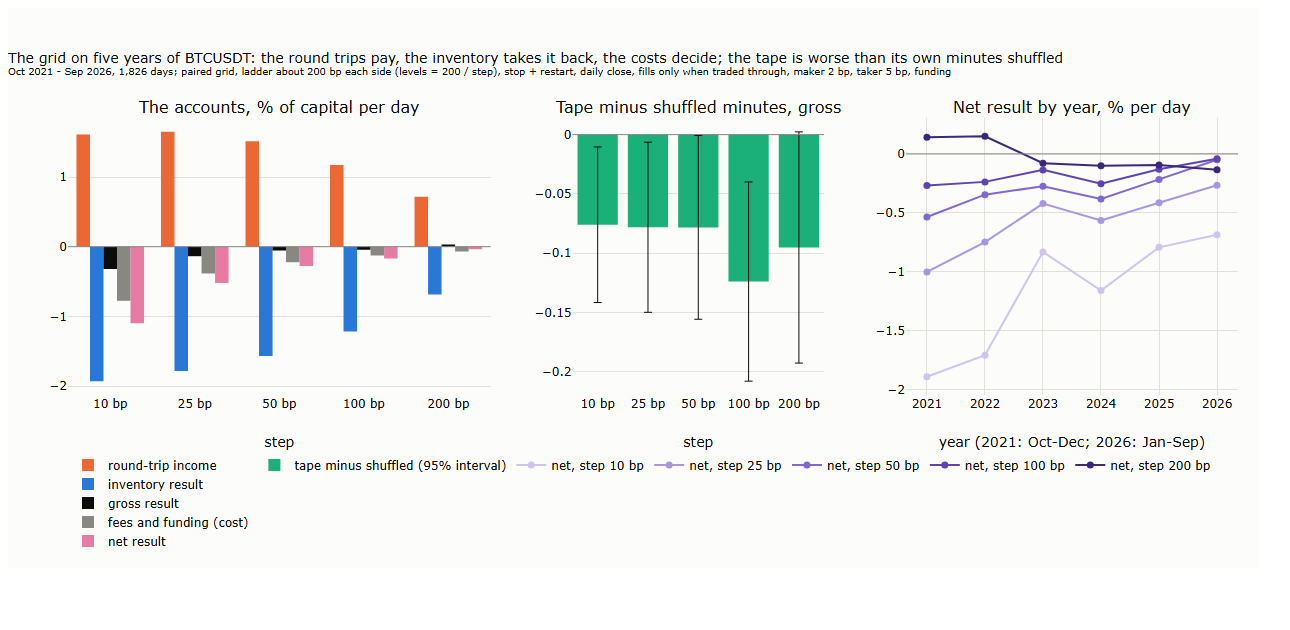

step,round trips,stops,net %,Sharpe,worst 1%
i32,f64,f64,f64,f64,f64
10,321.834064,1.628697,-1.097077,-9.382108,-10.546367
25,52.734392,1.412924,-0.520402,-5.779903,-7.118366
50,12.10241,1.122673,-0.278266,-3.490645,-5.359956
100,2.343373,0.745893,-0.170719,-2.041548,-6.03133
200,0.357612,0.363089,-0.037765,-0.393839,-4.761116


In [5]:
run("l17_tape_vs_shuffled.py", makes="l17_tape_vs_shuffled.parquet")
run("l17_s3_chart.py")
pictures("17_04_tape")
R = pl.read_parquet(OUT / "l17_tape_vs_shuffled.parquet").filter(pl.col("path") == "tape")
R.group_by("step").agg(pl.col("trips").mean().alias("round trips"), pl.col("stops").mean(), pl.col("net").mean().alias("net %"),
                       (pl.col("net").mean() / pl.col("net").std() * np.sqrt(365)).alias("Sharpe"), pl.col("net").quantile(0.01).alias("worst 1%")).sort("step")

## 4. The levers

Lecture §4. Width, exits and refresh; the four size profiles on the tape and on simulated prices by regime; the stylised profiles (figures 17_05 to 17_07).

l17_levers.py: skipped, l17_levers.parquet exists
l17_shapes.py: skipped, l17_shapes.parquet exists
l17_shapes_mc.py: skipped, l17_shapes_mc.json exists


l17_s4_shapes_chart.py: 4 s


l17_s4_charts.py: 5 s


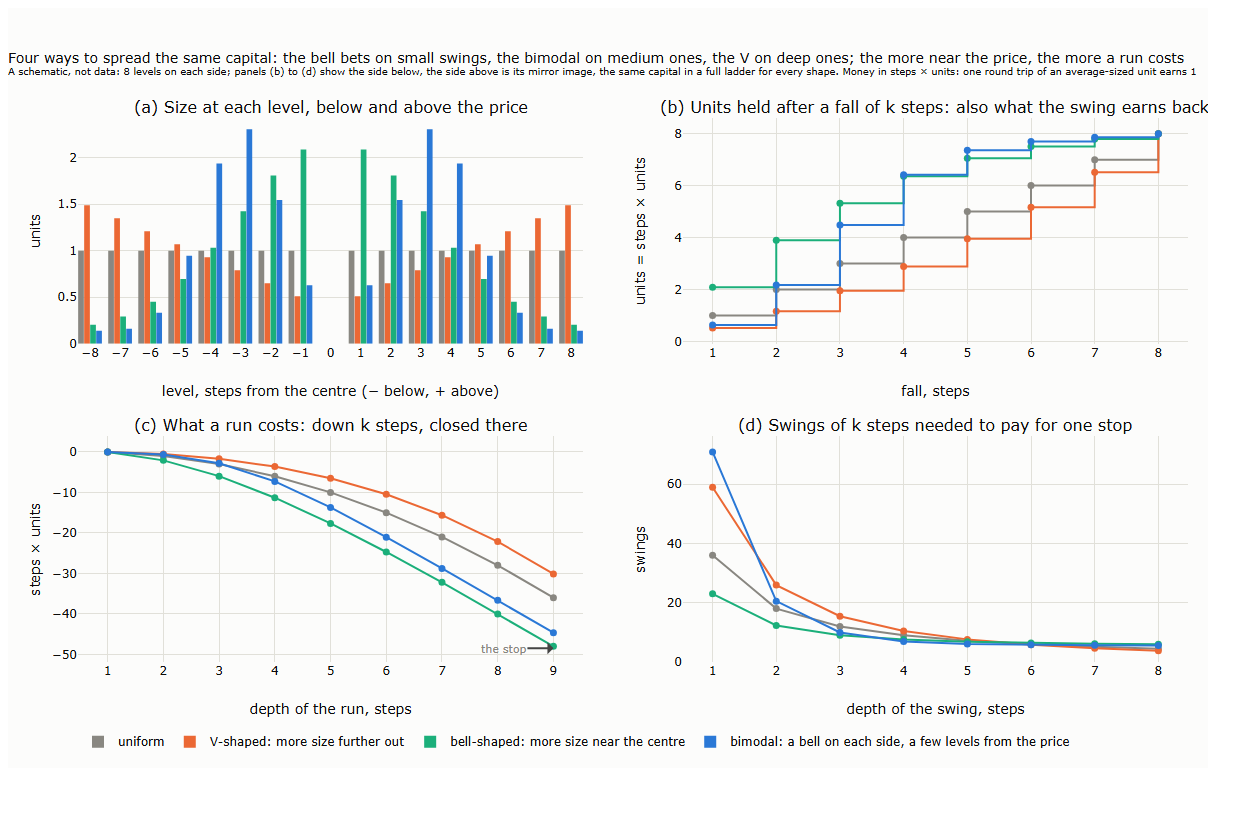

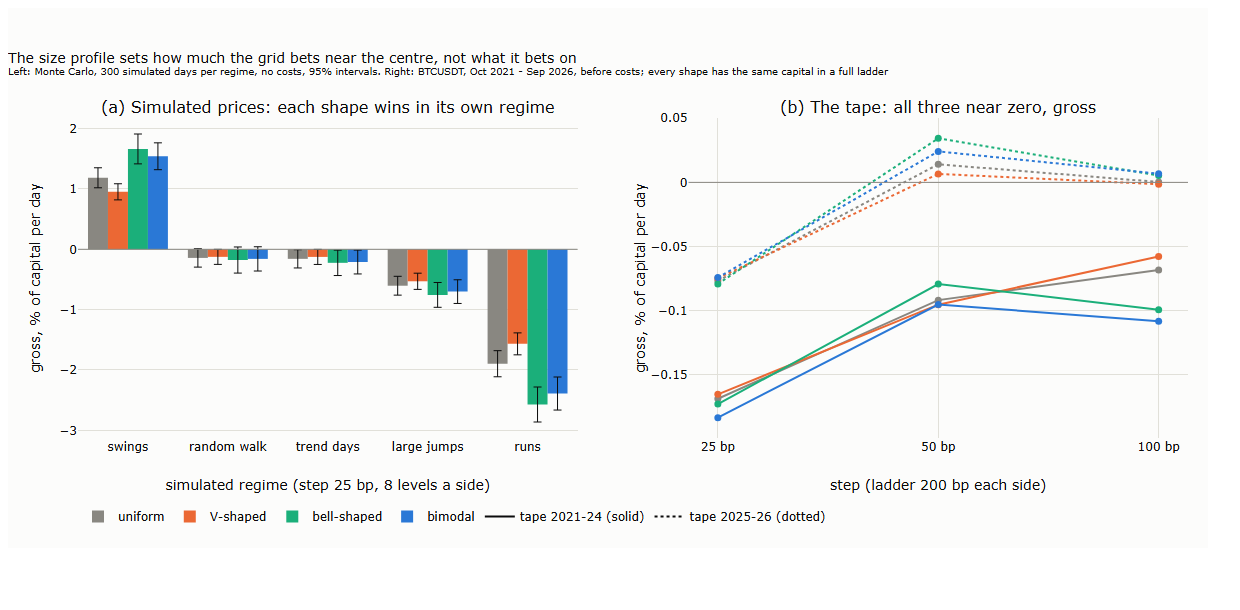

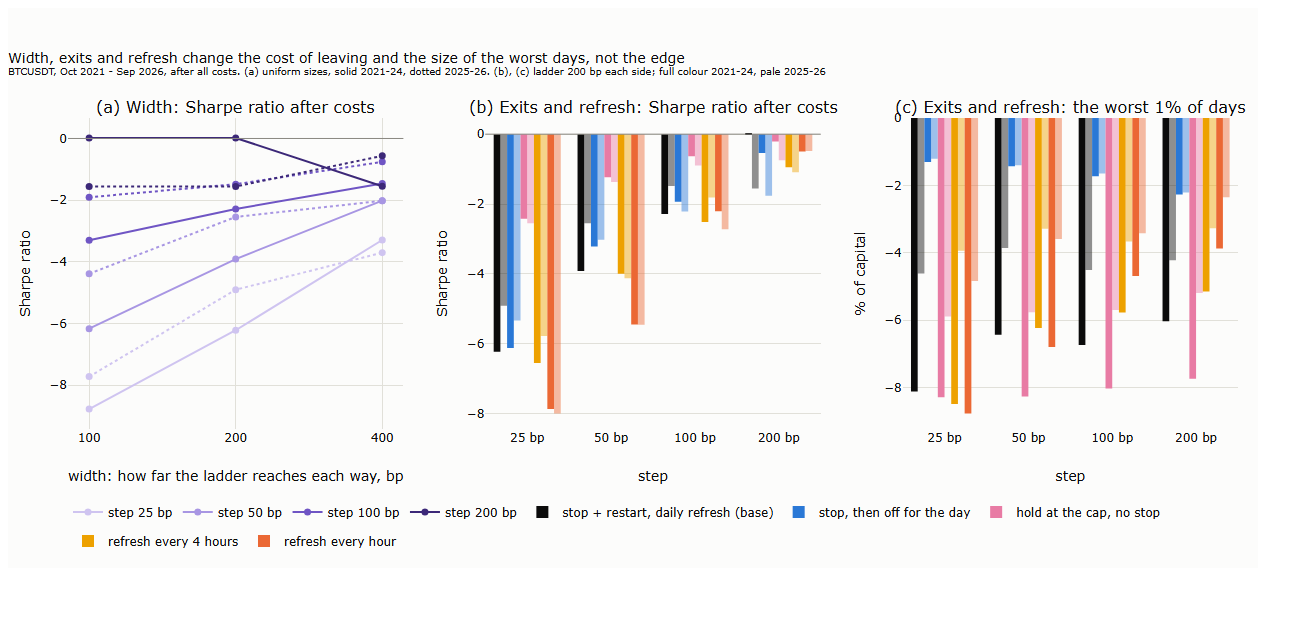

regime,bell-shaped,uniform,V-shaped,bimodal
str,f64,f64,f64,f64
"""random walk""",-0.177602,-0.14262,-0.125117,-0.158828
"""large jumps""",-0.755415,-0.603392,-0.529958,-0.701243
"""trend days""",-0.224158,-0.158068,-0.125915,-0.210587
"""runs""",-2.571927,-1.895941,-1.566949,-2.390202
"""swings""",1.663475,1.185293,0.952577,1.54195


In [6]:
run("l17_levers.py", makes="l17_levers.parquet"); run("l17_shapes.py", makes="l17_shapes.parquet"); run("l17_shapes_mc.py", makes="l17_shapes_mc.json")
run("l17_s4_shapes_chart.py"); run("l17_s4_charts.py")
pictures("17_05_shapes", "17_06_shapes_regimes", "17_07_levers")
pl.DataFrame(result("l17_shapes_mc.json")).filter(pl.col("step") == 25).pivot(on="shape", index="regime", values="gross")

In [7]:
L = period(pl.read_parquet(OUT / "l17_levers.parquet")).filter(pl.col("step") == 50)
L.group_by("rule", "period").agg((pl.col("net").mean() / pl.col("net").std() * np.sqrt(365)).alias("Sharpe"), pl.col("net").quantile(0.01).alias("worst 1%"),
                                 pl.col("stops").mean()).pivot(on="period", index="rule", values=["Sharpe", "worst 1%", "stops"]).sort("rule")

rule,Sharpe_2021-24,Sharpe_2025-26,worst 1%_2021-24,worst 1%_2025-26,stops_2021-24,stops_2025-26
str,f64,f64,f64,f64,f64,f64
"""base""",-3.913778,-2.545984,-6.435098,-3.861014,1.335859,0.725705
"""hold at the cap""",-1.232683,-1.371244,-8.272814,-5.767661,0.0,0.0
"""levels 2""",-6.172093,-4.391685,-9.425988,-5.350634,3.896465,2.275862
"""levels 4""",-3.913778,-2.545984,-6.435098,-3.861014,1.335859,0.725705
"""levels 8""",-2.016907,-2.021307,-5.063626,-3.612768,0.340909,0.167712
"""refresh every 4 hours""",-3.992088,-4.119922,-6.234287,-3.286612,0.931818,0.413793
"""refresh every hour""",-5.446577,-5.450912,-6.800947,-3.594674,0.55303,0.195925
"""stop, off for the day""",-3.214812,-3.018573,-1.435548,-1.40029,0.548822,0.420063


## 5. Known in advance

Lecture §5. The volatility switch, the rules added to it, the hours of the day; the two questions, each corrected for its number of tests
(figure 17_08). `l17_directions.py` imports the trend forecast of Lecture 16.

l17_volswitch.py: skipped, l17_volswitch.parquet exists
l17_directions.py: skipped, l17_directions.parquet exists


l17_s5_tests.py: 7 s
Q1: does the rule cut losses (net vs baseline)?
shape: (28, 8)
┌──────┬─────────────────────┬────────┬────────┬───────┬───────┬──────────┬────────────┐
│ step ┆ rule                ┆ diff   ┆ t_diff ┆ q     ┆ bh    ┆ diff_oos ┆ t_diff_oos │
│ ---  ┆ ---                 ┆ ---    ┆ ---    ┆ ---   ┆ ---   ┆ ---      ┆ ---        │
│ i64  ┆ str                 ┆ f64    ┆ f64    ┆ f64   ┆ bool  ┆ f64      ┆ f64        │
╞══════╪═════════════════════╪════════╪════════╪═══════╪═══════╪══════════╪════════════╡
│ 25   ┆ channel             ┆ 0.005  ┆ 0.775  ┆ 0.330 ┆ false ┆ -0.002   ┆ -0.401     │
│ 50   ┆ channel             ┆ -0.000 ┆ -0.060 ┆ 0.699 ┆ false ┆ 0.001    ┆ 0.082      │
│ 100  ┆ channel             ┆ -0.007 ┆ -0.652 ┆ 0.800 ┆ false ┆ -0.000   ┆ -0.046     │
│ 200  ┆ channel             ┆ 0.009  ┆ 1.094  ┆ 0.226 ┆ false ┆ 0.006    ┆ 0.794      │
│ 25   ┆ off above 1.5       ┆ 0.345  ┆ 6.885  ┆ 0.000 ┆ true  ┆ 0.209    ┆ 4.059      │
│ 50   ┆ off above 1.5    

l17_s5_chart.py: 3 s


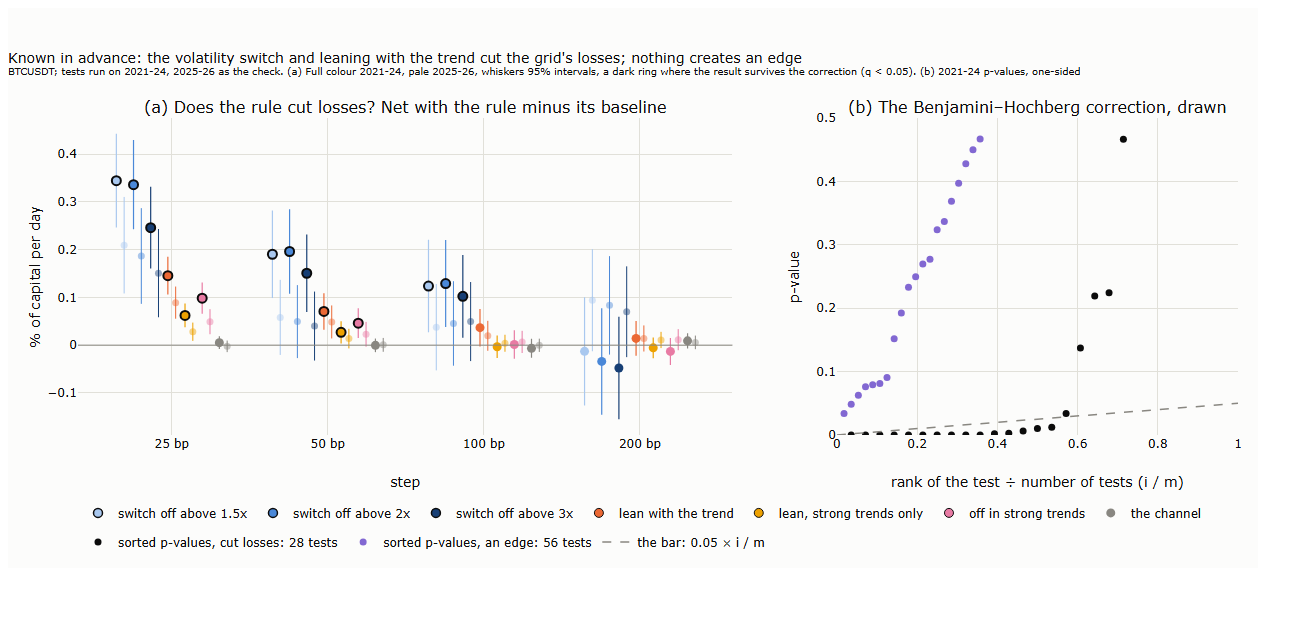

In [8]:
run("l17_volswitch.py", makes="l17_volswitch.parquet"); run("l17_directions.py", makes="l17_directions.parquet")
run("l17_s5_tests.py", show=True); run("l17_s5_chart.py")
pictures("17_08_known_in_advance")

## 6. Next to the trend rule

Lecture §6. The rule for adding a strategy, portfolios of the trend rule of Lecture 16 and the grid, and the grid by the size of the trend forecast
at the start of the day (figure 17_09).

l17_s6.py: 1 s


l17_s6_chart.py: 3 s


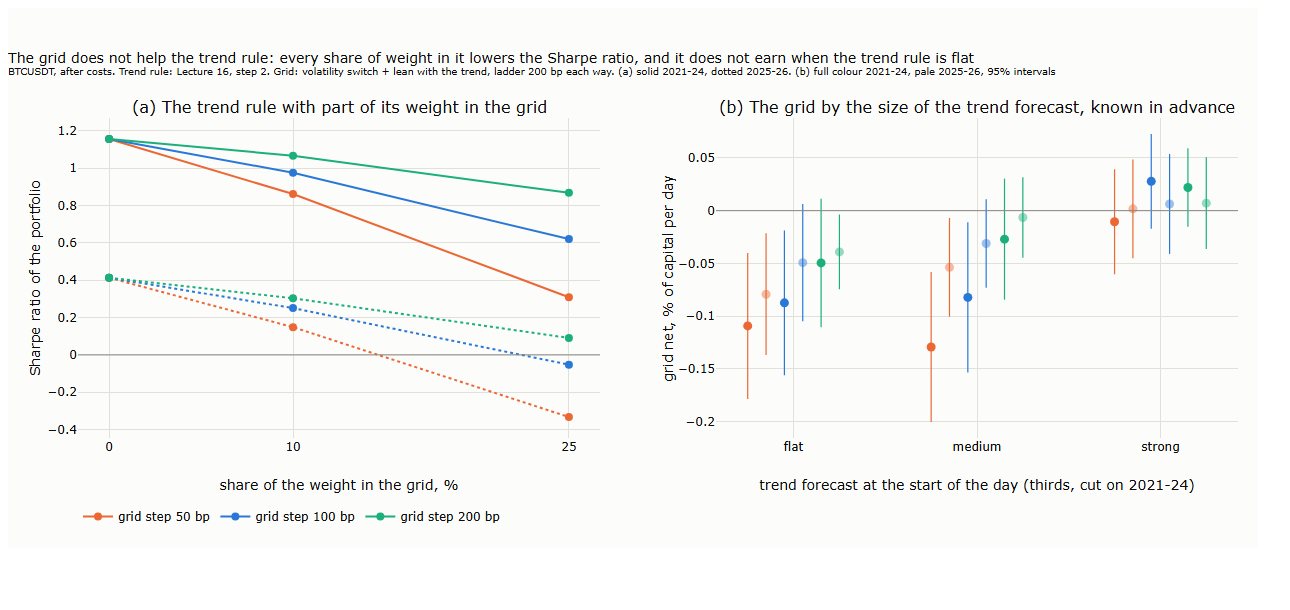

rule,step,p,rho,sr_grid,sr_trend,w10,w25
str,i64,str,f64,f64,f64,f64,f64
"""skew, sign""",50,"""2021-24""",0.202571,-2.432839,1.155819,0.861149,0.308938
"""skew, sign""",50,"""2025-26""",0.179985,-2.345409,0.413078,0.148637,-0.332319
"""skew, sign""",100,"""2021-24""",0.15945,-1.415009,1.155819,0.975562,0.620058
"""skew, sign""",100,"""2025-26""",0.153293,-1.411046,0.413078,0.250547,-0.051993
"""skew, sign""",200,"""2021-24""",0.094549,-0.6472,1.155819,1.06627,0.867574
"""skew, sign""",200,"""2025-26""",0.093201,-0.943723,0.413078,0.303249,0.090941
"""vol switch (base)""",50,"""2021-24""",0.011503,-3.140021,1.155819,0.800981,0.103188
"""vol switch (base)""",50,"""2025-26""",-0.042912,-3.096429,0.413078,0.068934,-0.595006
"""vol switch (base)""",100,"""2021-24""",-0.014399,-1.686855,1.155819,0.963992,0.565524


In [9]:
run("l17_s6.py"); run("l17_s6_chart.py")
pictures("17_09_with_trend")
pl.DataFrame(result("l17_s6.json")).select("rule", "step", "p", "rho", "sr_grid", "sr_trend", "w10", "w25")

## 7. The rebate that would close the gap

Lecture §7: the maker rebate at which the grid breaks even, with the taker fee kept at 5 bp.

In [10]:
run("l17_s7.py")
pl.DataFrame(result("l17_s7.json")).pivot(on="p", index=["rule", "step"], values=["rebate_bp", "filled_x_capital"])

l17_s7.py: 1 s


rule,step,rebate_bp_2021-24,rebate_bp_2025-26,filled_x_capital_2021-24,filled_x_capital_2025-26
str,i64,f64,f64,f64,f64
"""always on""",25,1.556179,1.332895,17.195059,10.525221
"""always on""",50,2.024335,0.753663,8.692756,5.266342
"""always on""",100,3.286849,1.773418,4.028921,2.437701
"""always on""",200,-2.108346,9.284863,1.731246,0.988742
"""skew, sign""",25,1.430737,1.38443,3.781516,2.214422
"""skew, sign""",50,2.347484,2.348133,1.910617,1.083072
"""skew, sign""",100,3.400002,3.917052,0.876154,0.455436
"""skew, sign""",200,3.794627,9.6113,0.31422,0.122714
"""vol switch (base)""",25,1.393184,1.575972,8.11252,4.586798


## 8. A test of your own

Lecture §8.2: change one setting and run the grid on one month. `run` of `l17_grid` takes the step in bp, the number of levels a side, the size
profile (`"uniform"`, `"V-shaped"`, `"bell-shaped"`, `"bimodal"`), the fees, the exit (`stop`, `restart=1` for off for the rest of the day) and an
on-mask of the seconds the grid may trade.

In [11]:
import l17_grid as g
data = g.load("2024-03", "2024-03")
mine = g.run(data, 50, n=8, sizes="bimodal", restart=1)
mine.select(pl.col("gross", "trips_income", "inventory", "maker_fee", "taker_fee", "funding", "net").mean())

gross,trips_income,inventory,maker_fee,taker_fee,funding,net
f64,f64,f64,f64,f64,f64,f64
-0.633438,0.91822,-1.551659,0.087799,0.035396,0.010912,-0.745722
